## Acetaldehyde vs ethanol

In [32]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'analysis/scripts/config.py').is_file())
scripts = str(repo / 'analysis/scripts')
if scripts not in sys.path:
    sys.path.insert(0, scripts)

from config import COMBINED_DIR
import calibration

# Keep scans at one photon energy together. Use 268*7eV for the 268.7 eV scans.
SCAN_PATTERN = '*AcH_*delay_scan_*268.2eV*_aggregates_tr.h5'
FILES = sorted(COMBINED_DIR.glob(SCAN_PATTERN))
# FILES = [COMBINED_DIR / 'AcH_..._aggregates_tr.h5']
# FILES = FILES[-1:]

VLS_CAL_FILE = COMBINED_DIR / 'run60612_AcH_undulator_scan_part2_265-280eV_2809782740.h5'

GMD_BINS = None              # None: all; indices refer to each scan's own edges
FS_PER_STAGE_UNIT = 0.349 / 1000
Z_ZERO = 0                   # stage units
DELAY_SIGN = 1
NORMALISE = 'per_uJ'         # ions: 'per_uJ' or 'per_shot'
DELAY_BASELINE = None        # None: all delays; or (lo, hi) in fs

# Main electron spectra and traces (sections 5, 7 and 8).
MONITOR = 'vls'              # 'vls', 'gmd', 'shot'
USE_READY = False           # set True once every selected scan has a valid ready file
TAU_NS = 6                  # ns; check the plateau in section 4.1 before choosing
MONITOR_WINDOWS = [(10, 40), (210, 240), (240, 265)]
READY_WINDOWS = [(10, 40), (210, 285)]  # KE windows for the tau diagnostic
RUN_READY_DIAGNOSTICS = True

SCAN_MINUTES = {}
TRAIN_RATE = 10              # Hz
RUN_TIME_DIAGNOSTIC = False  # rereads combined files with the separate cuts stated below
RUN_FINE_IONS = False        # rereads combined files for a finer ion histogram

print(f'{len(FILES)} files selected:')
for path in FILES:
    print(path.name)

1 files selected:
AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5


In [47]:
# Read only the first moments and bin edges. D, C and G are means per shot.
if not FILES:
    raise FileNotFoundError('No delay aggregates found in ' + str(COMBINED_DIR))

scans = {}
axes = {}
for path in FILES:
    path = Path(path)
    with h5py.File(path, 'r') as f:
        if f.attrs['config'] != 1 or f.attrs['mode'] != 'time_resolved':
            raise ValueError(f'{path.name}: expected config 1 time_resolved aggregates')
        edges = {key: f[key][:] for key in ('z_edges', 'tof_edges', 'ion_tof_edges')}
        if not axes:
            axes = edges
        elif any(not np.array_equal(edges[key], axes[key]) for key in axes):
            raise ValueError(f'{path.name}: different delay or TOF edges. Select compatible scans.')

        n = f['n_per_bin'][:]
        D, C, G = f['D'][:], f['C'][:], f['G'][:]
        gmd_edges = f['gmd_edges'][:]
        attrs = dict(f.attrs)

    # Empty cells contain NaNs. Ignore them, not NaNs in populated cells.
    if any(not np.isfinite(a[n > 0]).all() for a in (D, C, G)):
        raise ValueError(f'{path.name}: non-finite means in populated bins')
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, D, C, G = n[bins], D[bins], C[bins], G[bins]
    # Convert means to sums before collapsing the GMD dimension.
    e = np.where(n[..., None] > 0, D, 0) * n[..., None]
    i = np.where(n[..., None] > 0, C, 0) * n[..., None]
    g = np.where(n > 0, G, 0) * n

    # Acquisition duration: read just the two train-ID endpoints.
    minutes = SCAN_MINUTES.get(path.name, np.nan)
    source = Path(attrs.get('input_h5', ''))
    if not source.is_absolute():
        source = repo / source
    if not source.is_file():
        source = COMBINED_DIR / path.name.replace('_aggregates_tr.h5', '.h5')
    if not np.isfinite(minutes) and source.is_file():
        with h5py.File(source, 'r') as f:
            if 'tID' in f and len(f['tID']):
                minutes = (int(f['tID'][-1]) - int(f['tID'][0]) + 1) / TRAIN_RATE / 60

    scans[path.name] = dict(n=n.sum(axis=0), e=e.sum(axis=0),
                            i=i.sum(axis=0), g=g.sum(axis=0),
                            minutes=minutes, gmd_edges=gmd_edges, attrs=attrs)
    s = scans[path.name]
    print(f'\n{path.name}')
    print(f'  shots = {s["n"].sum():,}; e = {s["e"].sum():,.0f}; i = {s["i"].sum():,.0f}')
    print(f'  occupied delay bins = {np.count_nonzero(s["n"])} / {len(s["n"])}; time = {minutes:.1f} min')
    print('  GMD edges (uJ):', np.round(gmd_edges, 3))
    print('  skipped z outside / NaN:', attrs.get('n_skipped_z_oor', '?'), attrs.get('n_skipped_z_nan', '?'))
    print('  skipped max hits:', attrs.get('n_skipped_max_hits', '?'))

# GMD percentile edges can differ by file. Pool counts, not means.
combined = {key: np.sum([s[key] for s in scans.values()], axis=0)
            for key in ('n', 'e', 'i', 'g')}
combined['minutes'] = sum(s['minutes'] for s in scans.values())
scans_raw, combined_raw = scans, combined
if GMD_BINS is not None:
    print("Note: selected GMD indices refer to each scan's own edges.")


AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5
  shots = 1,169,112; e = 959,164; i = 492,792
  occupied delay bins = 31 / 31; time = 20.0 min
  GMD edges (uJ): [0.02  0.093 0.179 0.297 0.506 4.265]
  skipped z outside / NaN: 0 0
  skipped max hits: 15


In [48]:
if DELAY_SIGN not in (-1, 1):
    raise ValueError('DELAY_SIGN must be +1 or -1')

z_edges = axes['z_edges']
delay_edges = DELAY_SIGN * (z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
ke_edges = calibration.ke_of_tof(axes['tof_edges'] / 10)[::-1]
mq_edges = calibration.mq_of_tof(axes['ion_tof_edges'] / 10)

# Keep all plotted axes increasing. Copy dictionaries so this cell can be rerun.
scans = {name: dict(s) for name, s in scans_raw.items()}
combined = dict(combined_raw)
for s in [*scans.values(), combined]:
    s['e'] = s['e'][:, ::-1]
    if DELAY_SIGN == -1:
        for key in ('n', 'e', 'i', 'g'):
            s[key] = s[key][::-1]
if DELAY_SIGN == -1:
    delay_edges = delay_edges[::-1]

delay = (delay_edges[:-1] + delay_edges[1:]) / 2
ke = (ke_edges[:-1] + ke_edges[1:]) / 2
mq = (mq_edges[:-1] + mq_edges[1:]) / 2
dke, dmq = np.diff(ke_edges), np.diff(mq_edges)

if any(np.any(~np.isfinite(edges)) or np.any(np.diff(edges) <= 0)
       for edges in (delay_edges, ke_edges, mq_edges)):
    raise ValueError('Calibrated edges must be finite and increasing')

# Safe division: empty exposure gives NaN, not zero signal.
def divide(a, b):
    a, b = np.broadcast_arrays(a, b)
    return np.divide(a, b, out=np.full(a.shape, np.nan, dtype=float), where=b > 0)

exposure_key = {'per_uJ': 'g', 'per_shot': 'n'}[NORMALISE]
unit = {'per_uJ': r'$\mu$J', 'per_shot': 'shot'}[NORMALISE]

print(f'Delay: {delay_edges[0]:.3f} to {delay_edges[-1]:.3f} fs, {len(delay)} bins')
print('Delay bin widths (fs):', np.unique(np.round(np.diff(delay_edges), 6)))
print(f'KE: {ke_edges[0]:.2f} to {ke_edges[-1]:.2f} eV')
print(f'm/q: {mq_edges[0]:.2f} to {mq_edges[-1]:.2f} u/e')

Delay: -15.356 to 15.356 fs, 31 bins
Delay bin widths (fs): [0.99071]
KE: 1.00 to 290.29 eV
m/q: 0.21 to 50.43 u/e


In [104]:
COMPARE_PATTERNS = {
    'Ethanol': '*Ethanol_short_delay_scan_*271_5eV*_aggregates_tr.h5',
    'Acetaldehyde': '*AcH*short_delay_scan_*_*268.2eV*_aggregates_tr.h5'
}

EXCLUDE_FILES = {
    'Ethanol_short_delay_scan_271_5eV_3rd_harmonic_2809252596_aggregates_tr',
}

SCAN_TYPE = 'short'       # 'short', 'long', or None
COMPARE_ROI = (220, 263)

molecules = {}
compare_axes = {}

for molecule, pattern in COMPARE_PATTERNS.items():

    files = sorted(COMBINED_DIR.glob(pattern))

    if SCAN_TYPE is not None:
        files = [p for p in files if SCAN_TYPE in p.name.lower()]

    files = [
        p for p in files
        if not any(excl in p.name for excl in EXCLUDE_FILES)
    ]

    if not files:
        raise FileNotFoundError(f'No scans found for {molecule}')

    print(f'\n{molecule}')
    results = []

    for path in files:

        with h5py.File(path, 'r') as f:

            if f.attrs['mode'] != 'time_resolved':
                raise ValueError(f'{path.name}: not a delay aggregate')

            for key in ('z_edges', 'tof_edges', 'ion_tof_edges'):

                edges = f[key][:]

                if key not in compare_axes:
                    compare_axes[key] = edges
                else:
                    np.testing.assert_array_equal(
                        edges, compare_axes[key],
                        err_msg=f'{path.name}: different {key}'
                    )

            n = f['n_per_bin'][:]
            D = f['D'][:]
            C = f['C'][:]
            G = f['G'][:]

            attrs = dict(f.attrs)

        # Use all GMD bins.
        # Convert per-shot means into recorded counts.
        if any(not np.isfinite(a[n > 0]).all()
               for a in (D, C, G)):
            raise ValueError(f'{path.name}: invalid populated cells')

        e = (np.where(n[..., None] > 0, D, 0)
             * n[..., None]).sum(axis=0)[:, ::-1]

        ions = (np.where(n[..., None] > 0, C, 0)
                * n[..., None]).sum(axis=0)

        g = (np.where(n > 0, G, 0) * n).sum(axis=0)
        shots = n.sum(axis=0)

        # Acquisition duration from the original combined file.
        minutes = SCAN_MINUTES.get(path.name, np.nan)

        source = Path(attrs.get('input_h5', ''))

        if not source.is_absolute():
            source = repo / source

        if not source.is_file():
            source = COMBINED_DIR / path.name.replace(
                '_aggregates_tr.h5', '.h5'
            )

        if not np.isfinite(minutes) and source.is_file():
            with h5py.File(source, 'r') as f:
                if 'tID' in f and len(f['tID']):
                    minutes = (
                        int(f['tID'][-1]) - int(f['tID'][0]) + 1
                    ) / TRAIN_RATE / 60

        results.append(dict(
            n=shots, e=e, i=ions, g=g,
            minutes=minutes
        ))

        print(f'  {path.name}')
        print(f'    {minutes:.1f} min | {shots.sum():,} shots')

    molecules[molecule] = {
        key: np.sum([s[key] for s in results], axis=0)
        for key in ('n', 'e', 'i', 'g')
    }

    molecules[molecule]['minutes'] = sum(
        s['minutes'] for s in results
    )

    molecules[molecule]['n_scans'] = len(results)


# Calibrated axes.
compare_delay_edges = DELAY_SIGN * (
    compare_axes['z_edges'] - Z_ZERO
) * FS_PER_STAGE_UNIT

compare_ke_edges = calibration.ke_of_tof(
    compare_axes['tof_edges'] / 10
)[::-1]

compare_ke = (
    compare_ke_edges[:-1] + compare_ke_edges[1:]
) / 2

if DELAY_SIGN == -1:

    compare_delay_edges = compare_delay_edges[::-1]

    for s in molecules.values():
        for key in ('n', 'e', 'i', 'g'):
            s[key] = s[key][::-1]

compare_delay = (
    compare_delay_edges[:-1] + compare_delay_edges[1:]
) / 2

compare_mask = (
    (compare_ke >= COMPARE_ROI[0]) &
    (compare_ke < COMPARE_ROI[1])
)

if not compare_mask.any():
    raise ValueError('Empty comparison ROI')

for s in molecules.values():
    s['roi'] = s['e'][:, compare_mask].sum(axis=1)


Ethanol
  Ethanol_short_delay_scan_1_271_5eV_2809266777_aggregates_tr.h5
    19.7 min | 1,152,242 shots
  Ethanol_short_delay_scan_2_271_5eV_2809279486_aggregates_tr.h5
    14.8 min | 863,467 shots
  Ethanol_short_delay_scan_3_271_5eV_2809292235_aggregates_tr.h5
    19.7 min | 1,155,314 shots

Acetaldehyde
  AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5
    20.0 min | 1,169,112 shots
  AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5
    20.0 min | 1,171,918 shots
  AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5
    20.0 min | 1,173,952 shots


In [105]:
# ---- Integrated signal levels --------------------------------------------

for molecule, s in molecules.items():

    N = s['n'].sum()
    E = s['e'].sum()
    I = s['i'].sum()
    R = s['roi'].sum()
    G = s['g'].sum()
    T = s['minutes']

    print(f'\n{molecule.upper()}')
    print('-' * 50)

    print(f'Number of scans:             {s["n_scans"]:12d}')
    print(f'Acquisition time (min):      {T:12.2f}')
    print(f'Total shots:                 {N:12,.0f}')
    print(f'Total electrons:             {E:12,.0f}')
    print(f'Total ROI electrons:         {R:12,.0f}')
    print(f'Total ions:                  {I:12,.0f}')

    print()

    print(f'Mean GMD (uJ/shot):          {divide(G, N):12.4f}')
    print(f'Electrons / shot:            {divide(E, N):12.4f}')
    print(f'ROI electrons / shot:        {divide(R, N):12.4f}')
    print(f'Ions / shot:                 {divide(I, N):12.4f}')

    print()

    print(f'Electrons / uJ:              {divide(E, G):12.4f}')
    print(f'ROI electrons / uJ:          {divide(R, G):12.4f}')
    print(f'Ions / uJ:                   {divide(I, G):12.4f}')

    print()

    print(f'Shots / min:                 {divide(N, T):12,.0f}')
    print(f'Electrons / min:             {divide(E, T):12,.0f}')
    print(f'ROI electrons / min:         {divide(R, T):12,.0f}')
    print(f'Ions / min:                  {divide(I, T):12,.0f}')

    print()

    print(f'Median ROI counts / bin:     {np.median(s["roi"]):12,.0f}')
    print(f'Median Poisson error (%):    '
          f'{np.nanmedian(divide(100, np.sqrt(s["roi"]))):12.3f}')


ETHANOL
--------------------------------------------------
Number of scans:                        3
Acquisition time (min):             54.20
Total shots:                    3,171,023
Total electrons:                3,095,313
Total ROI electrons:              677,012
Total ions:                       981,810

Mean GMD (uJ/shot):                0.3151
Electrons / shot:                  0.9761
ROI electrons / shot:              0.2135
Ions / shot:                       0.3096

Electrons / uJ:                    3.0983
ROI electrons / uJ:                0.6777
Ions / uJ:                         0.9827

Shots / min:                       58,501
Electrons / min:                   57,104
ROI electrons / min:               12,490
Ions / min:                        18,113

Median ROI counts / bin:           23,229
Median Poisson error (%):           0.656

ACETALDEHYDE
--------------------------------------------------
Number of scans:                        3
Acquisition time (min):        

## Raw metrics

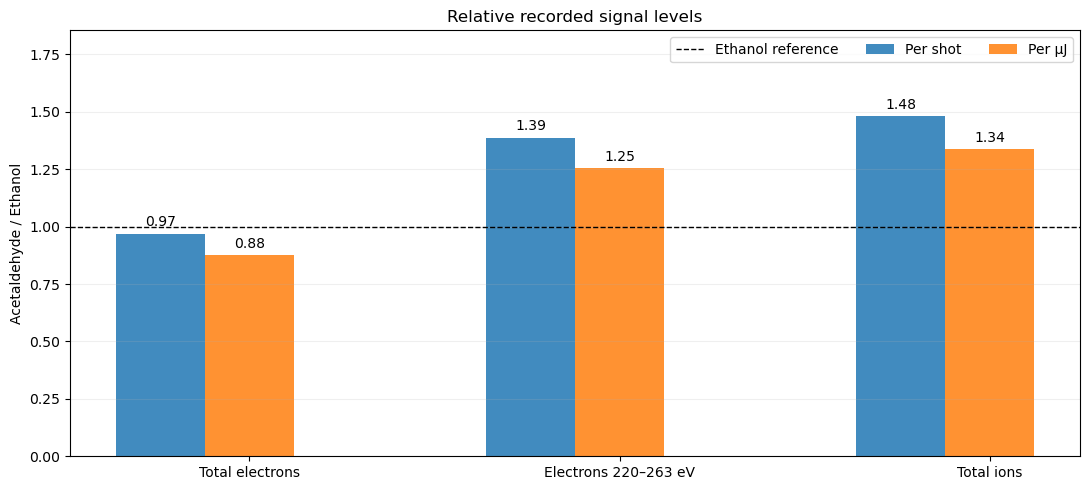

In [106]:
# ---- Relative signal levels: acetaldehyde / ethanol ----------------------

relative_metrics = {}

for molecule, s in molecules.items():

    N = s['n'].sum()
    E = s['e'].sum()
    R = s['roi'].sum()
    I = s['i'].sum()
    G = s['g'].sum()
    T = s['minutes']

    relative_metrics[molecule] = np.array([
        [E / N, R / N, I / N],
        [E / G, R / G, I / G],
        [E / T, R / T, I / T]
    ])

ratios = (relative_metrics['Acetaldehyde'] /
          relative_metrics['Ethanol'])

fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(3)
width = 0.24

for j, (label, color) in enumerate(zip(
        # ['Per shot', 'Per µJ', 'Per minute'],
        ['Per shot', 'Per µJ'],
        ['C0', 'C1', 'C2'])):

    bars = ax.bar(
        x + (j - 1) * width,
        ratios[j],
        width=width,
        label=label,
        color=color,
        alpha=0.85
    )

    ax.bar_label(bars, fmt='%.2f', padding=3)

ax.axhline(1, color='k', ls='--', lw=1,
           label='Ethanol reference')

ax.set_xticks(x)
ax.set_xticklabels([
    'Total electrons',
    f'Electrons {COMPARE_ROI[0]}–{COMPARE_ROI[1]} eV',
    'Total ions'
])

ax.set_ylabel('Acetaldehyde / Ethanol')
ax.set_title('Relative recorded signal levels')
ax.set_ylim(0, np.nanmax(ratios) * 1.25)
ax.legend(ncol=4)
ax.grid(axis='y', alpha=0.2)

fig.tight_layout()
plt.show()

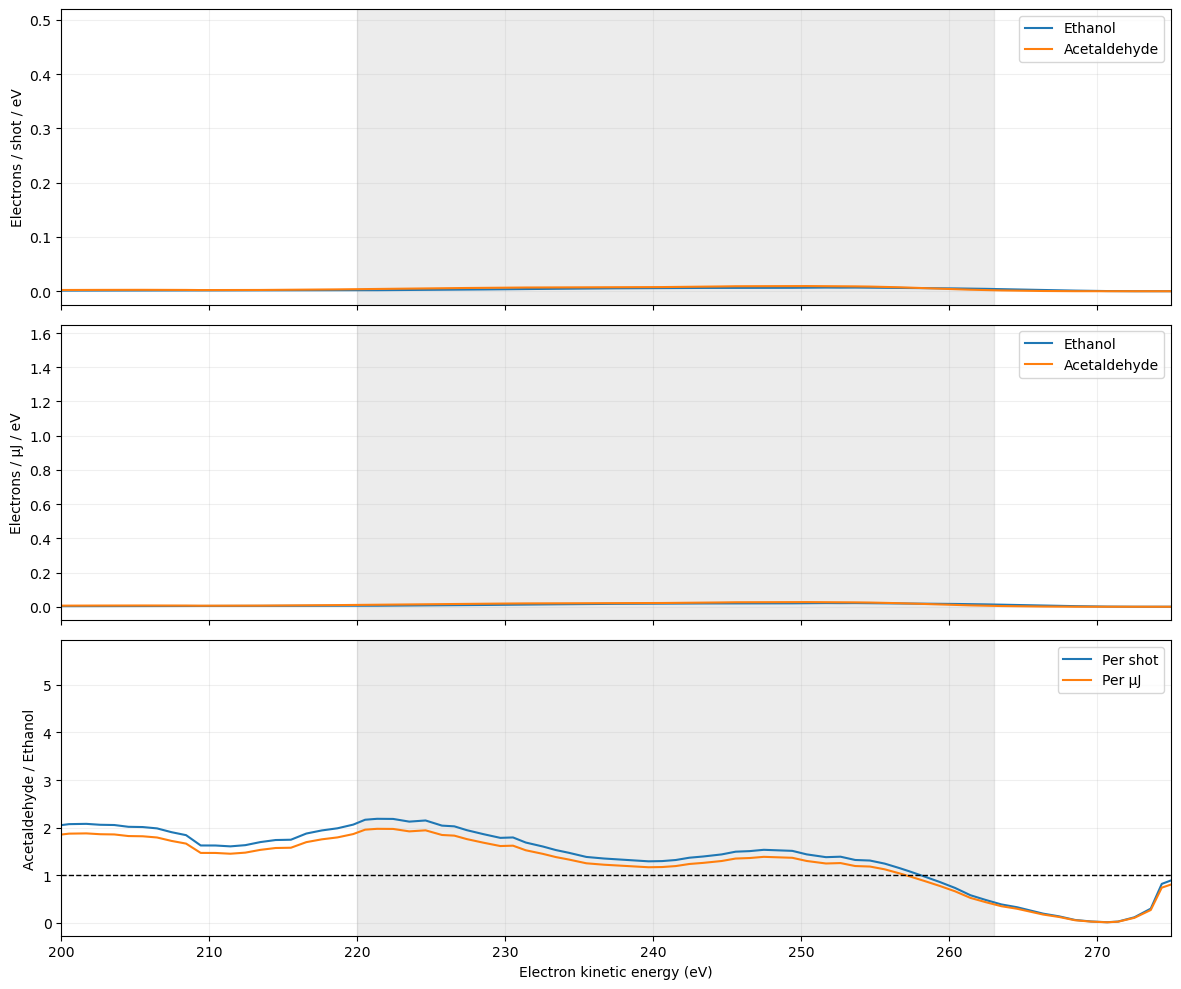

In [107]:
# ---- Electron spectra and relative signal levels ------------------------

molecule_colors = {
    'Ethanol': 'C0',
    'Acetaldehyde': 'C1'
}

compare_dke = np.abs(np.diff(compare_ke_edges))

spectra = {}

fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for molecule, s in molecules.items():

    e = s['e'].sum(axis=0)

    y_shot = e / s['n'].sum() / compare_dke
    y_gmd = e / s['g'].sum() / compare_dke

    spectra[molecule] = {
        'shot': y_shot,
        'gmd': y_gmd
    }

    ax[0].plot(compare_ke, y_shot,
               color=molecule_colors[molecule],
               label=molecule)

    ax[1].plot(compare_ke, y_gmd,
               color=molecule_colors[molecule],
               label=molecule)

# Acetaldehyde / ethanol ratio.
for key, label, color in [
    ('shot', 'Per shot', 'C0'),
    ('gmd', 'Per µJ', 'C1')
]:

    num = spectra['Acetaldehyde'][key]
    den = spectra['Ethanol'][key]

    ratio = np.divide(
        num, den,
        out=np.full_like(num, np.nan),
        where=den > 0
    )

    ax[2].plot(compare_ke, ratio,
               color=color, label=label)

ax[0].set_ylabel('Electrons / shot / eV')
ax[1].set_ylabel('Electrons / µJ / eV')
ax[2].set_ylabel('Acetaldehyde / Ethanol')

ax[2].axhline(1, color='k', ls='--', lw=1)

for a in ax:

    a.axvspan(*COMPARE_ROI, color='grey', alpha=0.15)
    a.set_xlim(200, 275)
    a.grid(alpha=0.2)
    a.legend()

ax[-1].set_xlabel('Electron kinetic energy (eV)')

fig.tight_layout()
plt.show()

In [108]:
# ---- Load dead-time-corrected spectra ------------------------------------

TAU_NS = 6.0


def find_matching_scans(
    combined_dir,
    pattern,
    scan_type=None,
    exclude_files=(),
):
    files = sorted(combined_dir.glob(pattern))

    if scan_type is not None:
        files = [p for p in files if scan_type.lower() in p.name.lower()]

    if exclude_files:
        files = [
            p for p in files
            if not any(excl in p.name for excl in exclude_files)
        ]

    return files


corrected_spectra = {}

for molecule, pattern in COMPARE_PATTERNS.items():
    files = find_matching_scans(
        COMBINED_DIR,
        pattern,
        scan_type=SCAN_TYPE,
        exclude_files=EXCLUDE_FILES,
    )

    if not files:
        raise FileNotFoundError(f'No matching scans for {molecule}')

    e_recorded = np.zeros_like(compare_ke, dtype=float)
    e_corrected = np.zeros_like(compare_ke, dtype=float)

    print(f'\n{molecule}')

    for path in files:
        ready_path = path.with_name(f'{path.stem}_ready.h5')

        if not ready_path.exists():
            raise FileNotFoundError(f'Missing: {ready_path.name}')

        with h5py.File(path, 'r') as f:
            n = f['n_per_bin'][:]

        # Load dead-time-corrected data from ready_path here and accumulate
        # into e_recorded / e_corrected as needed.
            D = f['D'][:]
            tof_edges = f['tof_edges'][:]

        with h5py.File(ready_path, 'r') as f:

            taus = f['taus_ns'][:]
            tau_idx = np.flatnonzero(np.isclose(taus, TAU_NS))

            assert len(tau_idx) == 1, f'{TAU_NS} ns not found'
            assert f.attrs['check_n_equal'], 'Shot selection mismatch'

            np.testing.assert_array_equal(n, f['n_per_bin'][:])
            np.testing.assert_array_equal(tof_edges, f['tof_edges'][:])

            np.testing.assert_allclose(
                D[n > 0], f['D'][:][n > 0]
            )

            D_live = f['D_live'][tau_idx[0]]

        np.testing.assert_array_equal(
            tof_edges, compare_axes['tof_edges']
        )

        assert D_live.shape == D.shape

        if not np.isfinite(D_live[n > 0]).all():
            raise ValueError(
                f'{ready_path.name}: invalid corrected populated cells'
            )

        # Convert per-shot means to integrated electron yields.
        e_raw = (
            np.where(n[..., None] > 0, D, 0)
            * n[..., None]
        ).sum(axis=(0, 1))[::-1]

        e_live = (
            np.where(n[..., None] > 0, D_live, 0)
            * n[..., None]
        ).sum(axis=(0, 1))[::-1]

        e_recorded += e_raw
        e_corrected += e_live

        print(f'  {path.name}')
        print(f'    Total correction: {e_live.sum() / e_raw.sum():.3f}x')
        print(f'    ROI correction:   '
              f'{e_live[compare_mask].sum() / e_raw[compare_mask].sum():.3f}x')

    # Verify that we are using the same dataset as before.
    assert len(files) == molecules[molecule]['n_scans']

    np.testing.assert_allclose(
        e_recorded, molecules[molecule]['e'].sum(axis=0)
    )

    corrected_spectra[molecule] = {
        'recorded': e_recorded,
        'corrected': e_corrected
    }


Ethanol
  Ethanol_short_delay_scan_1_271_5eV_2809266777_aggregates_tr.h5
    Total correction: 1.023x
    ROI correction:   1.087x
  Ethanol_short_delay_scan_2_271_5eV_2809279486_aggregates_tr.h5
    Total correction: 1.021x
    ROI correction:   1.092x
  Ethanol_short_delay_scan_3_271_5eV_2809292235_aggregates_tr.h5
    Total correction: 1.019x
    ROI correction:   1.097x

Acetaldehyde
  AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5
    Total correction: 1.043x
    ROI correction:   1.127x
  AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5
    Total correction: 1.044x
    ROI correction:   1.136x
  AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5
    Total correction: 1.044x
    ROI correction:   1.145x


In [109]:
# ---- Integrated VLS intensity for molecular comparison ------------------

VLS_SCALE = 1e4

for molecule, pattern in COMPARE_PATTERNS.items():
    files = find_matching_scans(
        COMBINED_DIR,
        pattern,
        scan_type=SCAN_TYPE,
        exclude_files=EXCLUDE_FILES,
    )

    if not files:
        raise FileNotFoundError(f'No matching scans for {molecule}')

    total_vls = 0.0
    total_shots = 0
    total_gmd = 0.0

    print(f'\n{molecule}')

    for path in files:
        with h5py.File(path, 'r') as f:
            if 'A' not in f:
                raise KeyError(f'{path.name}: no VLS aggregates')

            A = f['A'][:]
            n = f['n_per_bin'][:]
            G = f['G'][:]

        assert A.shape[:-1] == n.shape

        if not np.isfinite(A[n > 0]).all():
            raise ValueError(f'{path.name}: invalid VLS data')

        # Integrated Gotthard intensity per shot in each cell.
        M = A.sum(axis=-1) / VLS_SCALE

        if np.any(M[n > 0] <= 0):
            raise ValueError(
                f'{path.name}: non-positive VLS monitor'
            )

        # Weight by the number of shots in each cell.
        vls_sum = np.sum(M[n > 0] * n[n > 0])

        total_vls += vls_sum
        total_shots += n.sum()
        total_gmd += np.sum(G[n > 0] * n[n > 0])

        print(f'  {path.name}')
        print(f'    Mean VLS / shot: {vls_sum / n.sum():.4f}')

    # Check consistency with the previous comparison.
    assert len(files) == molecules[molecule]['n_scans']

    np.testing.assert_equal(
        total_shots, molecules[molecule]['n'].sum()
    )

    np.testing.assert_allclose(
        total_gmd, molecules[molecule]['g'].sum()
    )

    molecules[molecule]['vls'] = total_vls

    print(f'\n  Mean VLS / shot: {total_vls / total_shots:.4f}')
    print(f'  VLS / GMD:       {total_vls / total_gmd:.4f}')


Ethanol
  Ethanol_short_delay_scan_1_271_5eV_2809266777_aggregates_tr.h5
    Mean VLS / shot: 0.7368
  Ethanol_short_delay_scan_2_271_5eV_2809279486_aggregates_tr.h5
    Mean VLS / shot: 0.7674
  Ethanol_short_delay_scan_3_271_5eV_2809292235_aggregates_tr.h5
    Mean VLS / shot: 0.8212

  Mean VLS / shot: 0.7759
  VLS / GMD:       2.4627

Acetaldehyde
  AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5
    Mean VLS / shot: 0.5862
  AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5
    Mean VLS / shot: 0.6543
  AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5
    Mean VLS / shot: 0.6986

  Mean VLS / shot: 0.6465
  VLS / GMD:       1.8545


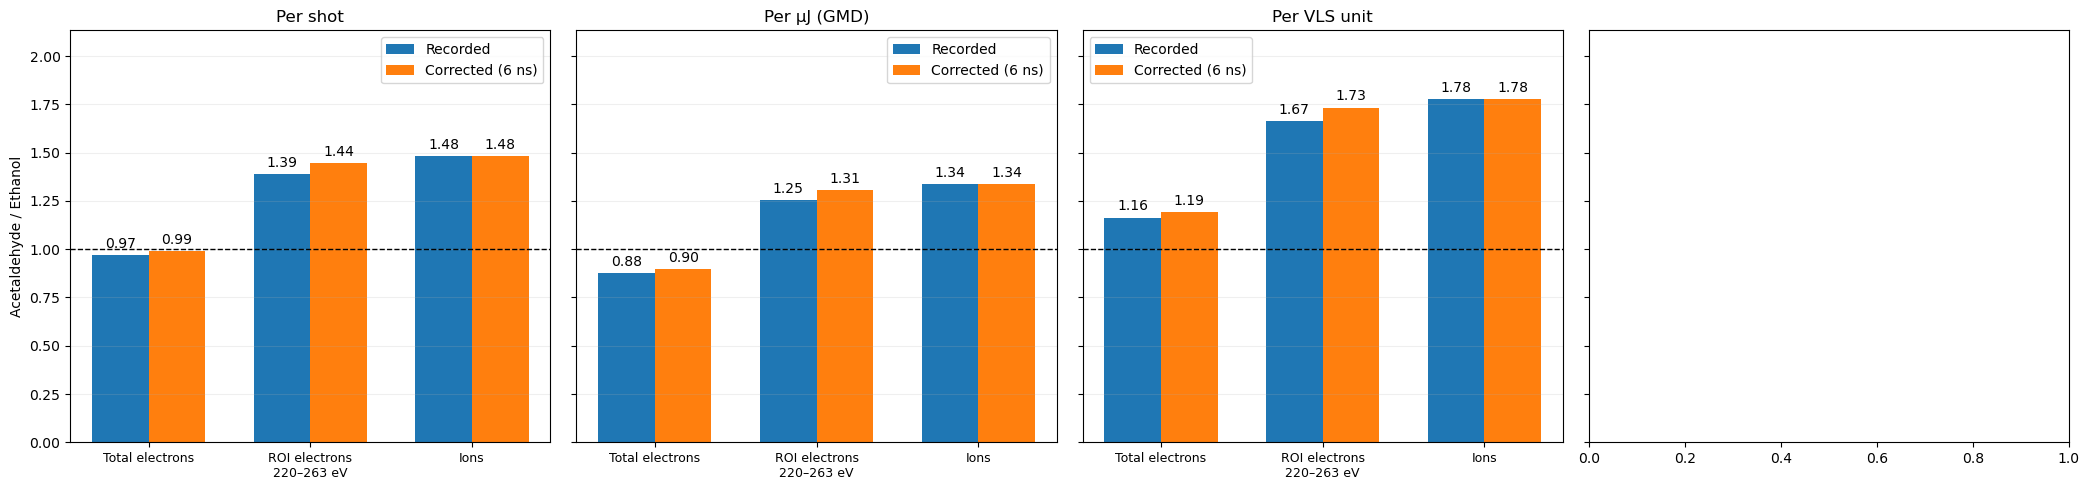

In [110]:
# ---- Relative signal levels before and after correction -----------------

relative_metrics = {}

for molecule, s in molecules.items():

    N = s['n'].sum()
    G = s['g'].sum()
    M = s['vls']
    T = s['minutes']
    I = s['i'].sum()

    relative_metrics[molecule] = {}

    for method in ('recorded', 'corrected'):

        e = corrected_spectra[molecule][method]

        E = e.sum()
        R = e[compare_mask].sum()

        relative_metrics[molecule][method] = np.array([
            [E / N, R / N, I / N],
            [E / G, R / G, I / G],
            [E / M, R / M, I / M],
            [E / T, R / T, I / T]
        ])

ratio_raw = (
    relative_metrics['Acetaldehyde']['recorded'] /
    relative_metrics['Ethanol']['recorded']
)

ratio_live = (
    relative_metrics['Acetaldehyde']['corrected'] /
    relative_metrics['Ethanol']['corrected']
)

fig, ax = plt.subplots(1, 4, figsize=(21, 5), sharey=True)

x = np.arange(3)
width = 0.35

titles = [
    'Per shot',
    'Per µJ (GMD)',
    'Per VLS unit'
    # 'Per minute'
]

for j, title in enumerate(titles):

    bars1 = ax[j].bar(
        x - width / 2, ratio_raw[j],
        width=width, color='C0',
        label='Recorded'
    )

    bars2 = ax[j].bar(
        x + width / 2, ratio_live[j],
        width=width, color='C1',
        label=f'Corrected ({TAU_NS:g} ns)'
    )

    ax[j].bar_label(bars1, fmt='%.2f', padding=3)
    ax[j].bar_label(bars2, fmt='%.2f', padding=3)

    ax[j].axhline(1, color='k', ls='--', lw=1)

    ax[j].set_xticks(x)
    ax[j].set_xticklabels([
        'Total electrons',
        f'ROI electrons\n{COMPARE_ROI[0]}–{COMPARE_ROI[1]} eV',
        'Ions'
    ], fontsize=9)

    ax[j].set_title(title)
    ax[j].grid(axis='y', alpha=0.2)
    ax[j].legend()

ax[0].set_ylabel('Acetaldehyde / Ethanol')

ax[0].set_ylim(
    0, 1.2 * max(np.nanmax(ratio_raw), np.nanmax(ratio_live))
)

fig.tight_layout()
plt.show()

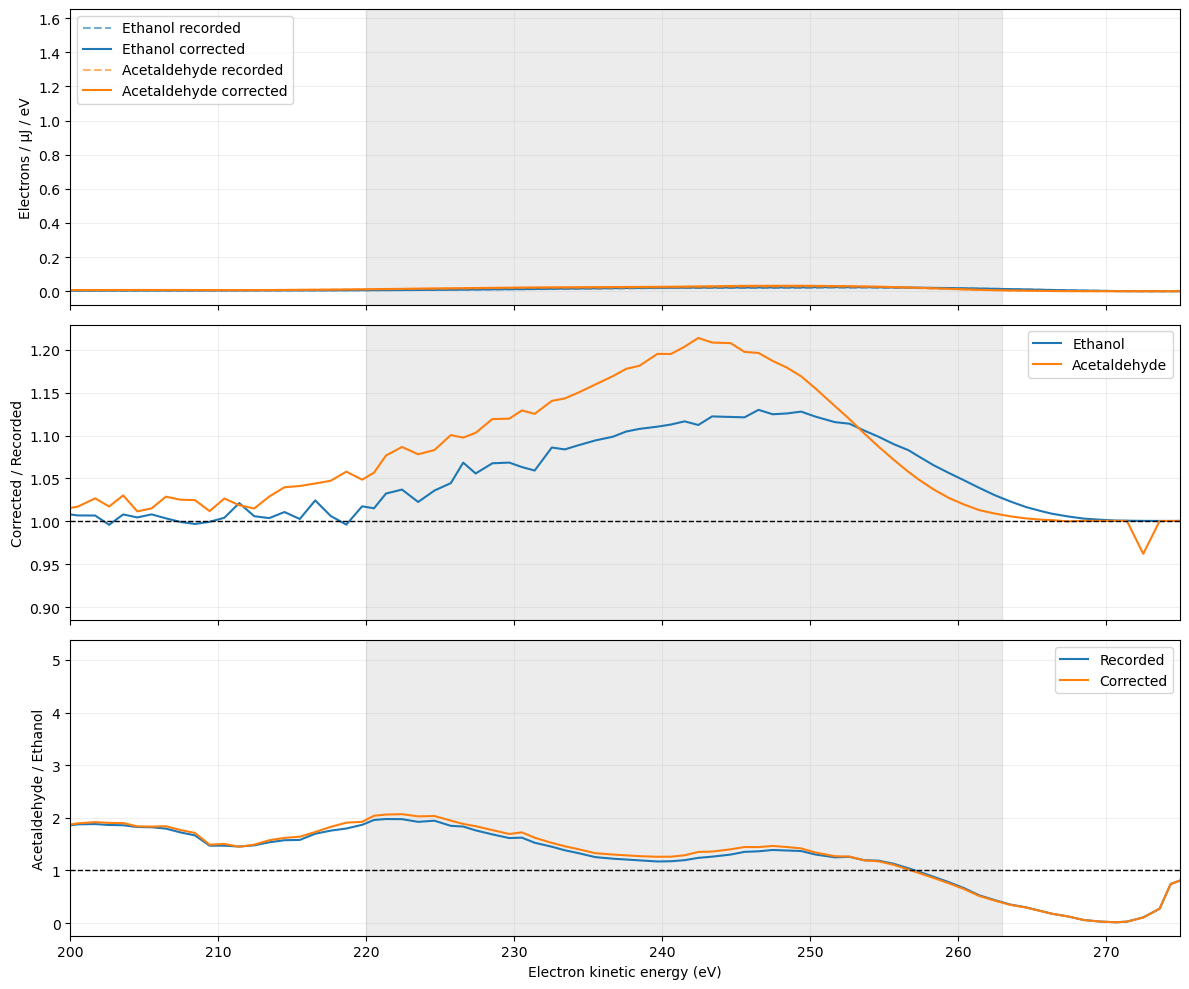

In [111]:
# ---- Energy-dependent correction and molecular ratio --------------------

fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

molecule_colors = {
    'Ethanol': 'C0',
    'Acetaldehyde': 'C1'
}

compare_dke = np.abs(np.diff(compare_ke_edges))

for molecule, s in molecules.items():

    raw = corrected_spectra[molecule]['recorded']
    live = corrected_spectra[molecule]['corrected']

    G = s['g'].sum()

    color = molecule_colors[molecule]

    ax[0].plot(
        compare_ke, raw / G / compare_dke,
        color=color, ls='--', alpha=0.6,
        label=f'{molecule} recorded'
    )

    ax[0].plot(
        compare_ke, live / G / compare_dke,
        color=color,
        label=f'{molecule} corrected'
    )

    factor = np.divide(
        live, raw,
        out=np.full_like(raw, np.nan),
        where=raw > 0
    )

    ax[1].plot(
        compare_ke, factor,
        color=color, label=molecule
    )

# Acetaldehyde / ethanol, normalised by GMD.
for method, color in [('recorded', 'C0'), ('corrected', 'C1')]:

    num = (
        corrected_spectra['Acetaldehyde'][method] /
        molecules['Acetaldehyde']['g'].sum()
    )

    den = (
        corrected_spectra['Ethanol'][method] /
        molecules['Ethanol']['g'].sum()
    )

    ratio = np.divide(
        num, den,
        out=np.full_like(num, np.nan),
        where=den > 0
    )

    ax[2].plot(compare_ke, ratio,
               color=color, label=method.capitalize())

ax[0].set_ylabel('Electrons / µJ / eV')
ax[1].set_ylabel('Corrected / Recorded')
ax[2].set_ylabel('Acetaldehyde / Ethanol')

ax[1].axhline(1, color='k', ls='--', lw=1)
ax[2].axhline(1, color='k', ls='--', lw=1)

for a in ax:

    a.axvspan(*COMPARE_ROI, color='grey', alpha=0.15)
    a.set_xlim(200, 275)
    a.grid(alpha=0.2)
    a.legend()

ax[-1].set_xlabel('Electron kinetic energy (eV)')

fig.tight_layout()
plt.show()

In [112]:
# ---- Shot-resolved FEL intensity and electron yields --------------------

from compute_aggregates import (
    _build_keep_mask,
    _vls_preprocess_block,
    _pedestal_part
)

TRAIN_STEP = 20       # 1 = all trains
CHUNK_TRAINS = 32
VLS_SCALE = 1e4

intensity_data = {}

for molecule, pattern in COMPARE_PATTERNS.items():

    files = sorted(COMBINED_DIR.glob(pattern))
    if not files:
        raise FileNotFoundError(molecule)

    samples = []

    print(f'\n{molecule}')

    for path in files:

        with h5py.File(path, 'r') as f:
            attrs = dict(f.attrs)

            gmd_edges = f['gmd_edges'][:]
            z_edges = f['z_edges'][:]
            tof_edges = f['tof_edges'][:]
            ion_edges = f['ion_tof_edges'][:]
            background = f['background'][:]

            expected_n = f['n_per_bin'][:].sum()

        np.testing.assert_array_equal(
            tof_edges, compare_axes['tof_edges']
        )

        source = Path(attrs['input_h5'])

        if not source.is_file():
            source = COMBINED_DIR / source.name

        if not source.is_file():
            raise FileNotFoundError(source)

        b0, b1 = attrs['bunch_range']
        p0, p1 = attrs['vls_crop_roi']

        bad = np.asarray(
            attrs['vls_bad_pixels'], dtype=int
        )

        bad_roi = bad[(bad >= p0) & (bad < p1)] - p0

        cm = None
        if 'vls_cm_pixels' in attrs:
            cm = np.arange(*attrs['vls_cm_pixels'])
            cm = cm[~np.isin(cm, bad)]

        roi_mask_tof = compare_mask[::-1]

        scan_samples = []

        with h5py.File(source, 'r') as f:

            if 'vls' not in f:
                raise KeyError(f'{source.name}: no VLS dataset')

            if not str(attrs.get('vls_source', '')).startswith('combined'):
                raise ValueError(
                    f'{path.name}: VLS not aggregated from combined file'
                )

            keep = _build_keep_mask(
                f,
                int(attrs['trim_start']),
                int(attrs['trim_end'])
            )

            rows = np.flatnonzero(keep)[::TRAIN_STEP]

            # Reproduce the original VLS pedestal.
            if attrs['vls_background_type'] == 'auto':

                bg0, bg1 = attrs['background_roi']

                ped_rows = np.flatnonzero(keep)[
                    ::int(attrs['vls_bg_stride'])
                ]

                ped_sum, ped_n = _pedestal_part(dict(
                    input_h5=str(source),
                    rows=ped_rows,
                    bg0=bg0,
                    bg1=bg1,
                    chunk=CHUNK_TRAINS,
                    vls_raw_run=None
                ))

                ped = ped_sum / np.maximum(ped_n, 1)

            elif attrs['vls_background_type'] == 'none':
                ped = np.zeros(f['vls'].shape[-1])

            else:
                raise ValueError('Unknown VLS background method')

            # Use the original stored pedestal inside the ROI.
            ped[p0:p1] = background

            for start in range(0, len(rows), CHUNK_TRAINS):

                r = rows[start:start + CHUNK_TRAINS]

                g = f['gmd'][r, b0:b1]
                z = f['z'][r, b0:b1]

                te = f['tofs_e'][r, b0:b1]
                ti = f['tofs_i'][r, b0:b1]

                A, vls_ok = _vls_preprocess_block(
                    f['vls'][r],
                    b0, b1, p0, p1,
                    ped, cm, bad_roi
                )

                M = A.sum(axis=-1) / VLS_SCALE

                # Same shot selection as the aggregates.
                valid = (
                    np.isfinite(g) &
                    (g >= gmd_edges[0]) &
                    (g < gmd_edges[-1]) &
                    np.isfinite(z) &
                    (z >= z_edges[0]) &
                    (z < z_edges[-1]) &
                    vls_ok
                )

                if 'max_hits_e' in attrs:
                    valid &= (
                        (te != 0).sum(axis=-1)
                        <= attrs['max_hits_e']
                    )

                if 'max_hits_i' in attrs:
                    valid &= (
                        (ti != 0).sum(axis=-1)
                        <= attrs['max_hits_i']
                    )

                if not np.isfinite(M[valid]).all():
                    raise ValueError('Non-finite VLS intensity')

                # Recorded electron counts within aggregate TOF range.
                e_valid = (
                    (te != 0) &
                    (te >= tof_edges[0]) &
                    (te <= tof_edges[-1])
                )

                e_total = e_valid.sum(axis=-1)

                # Same electron ROI as our previous comparison.
                idx = np.searchsorted(
                    tof_edges, te, side='right'
                ) - 1

                idx = np.clip(idx, 0, len(roi_mask_tof) - 1)

                e_roi = (
                    e_valid & roi_mask_tof[idx]
                ).sum(axis=-1)

                i_total = (
                    (ti != 0) &
                    (ti >= ion_edges[0]) &
                    (ti <= ion_edges[-1])
                ).sum(axis=-1)

                scan_samples.append(np.column_stack([
                    g[valid],
                    M[valid],
                    e_total[valid],
                    e_roi[valid],
                    i_total[valid]
                ]))

        scan_samples = np.concatenate(scan_samples)

        if TRAIN_STEP == 1:
            assert len(scan_samples) == expected_n, (
                f'{path.name}: shot selection mismatch'
            )

        samples.append(scan_samples)

        print(f'  {path.name}: {len(scan_samples):,} shots')

    intensity_data[molecule] = np.concatenate(samples)

    a = intensity_data[molecule]

    print(f'\n  Sampled shots:    {len(a):,}')
    print(f'  Mean GMD:         {a[:, 0].mean():.4f} µJ')
    print(f'  Mean VLS:         {a[:, 1].mean():.4f}')
    print(f'  Electrons / shot: {a[:, 2].mean():.4f}')
    print(f'  ROI e / shot:     {a[:, 3].mean():.4f}')


Ethanol
  Ethanol_short_delay_scan_1_271_5eV_2809266777_aggregates_tr.h5: 57,669 shots
  Ethanol_short_delay_scan_271_5eV_3rd_harmonic_2809252596_aggregates_tr.h5: 57,813 shots
  Ethanol_short_delay_scan_2_271_5eV_2809279486_aggregates_tr.h5: 43,170 shots
  Ethanol_short_delay_scan_3_271_5eV_2809292235_aggregates_tr.h5: 57,890 shots

  Sampled shots:    216,542
  Mean GMD:         0.3189 µJ
  Mean VLS:         0.5636
  Electrons / shot: 0.7092
  ROI e / shot:     0.1556

Acetaldehyde
  AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5: 58,510 shots
  AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5: 58,590 shots
  AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5: 58,742 shots

  Sampled shots:    175,842
  Mean GMD:         0.3469 µJ
  Mean VLS:         0.6417
  Electrons / shot: 0.9409
  ROI e / shot:     0.2950


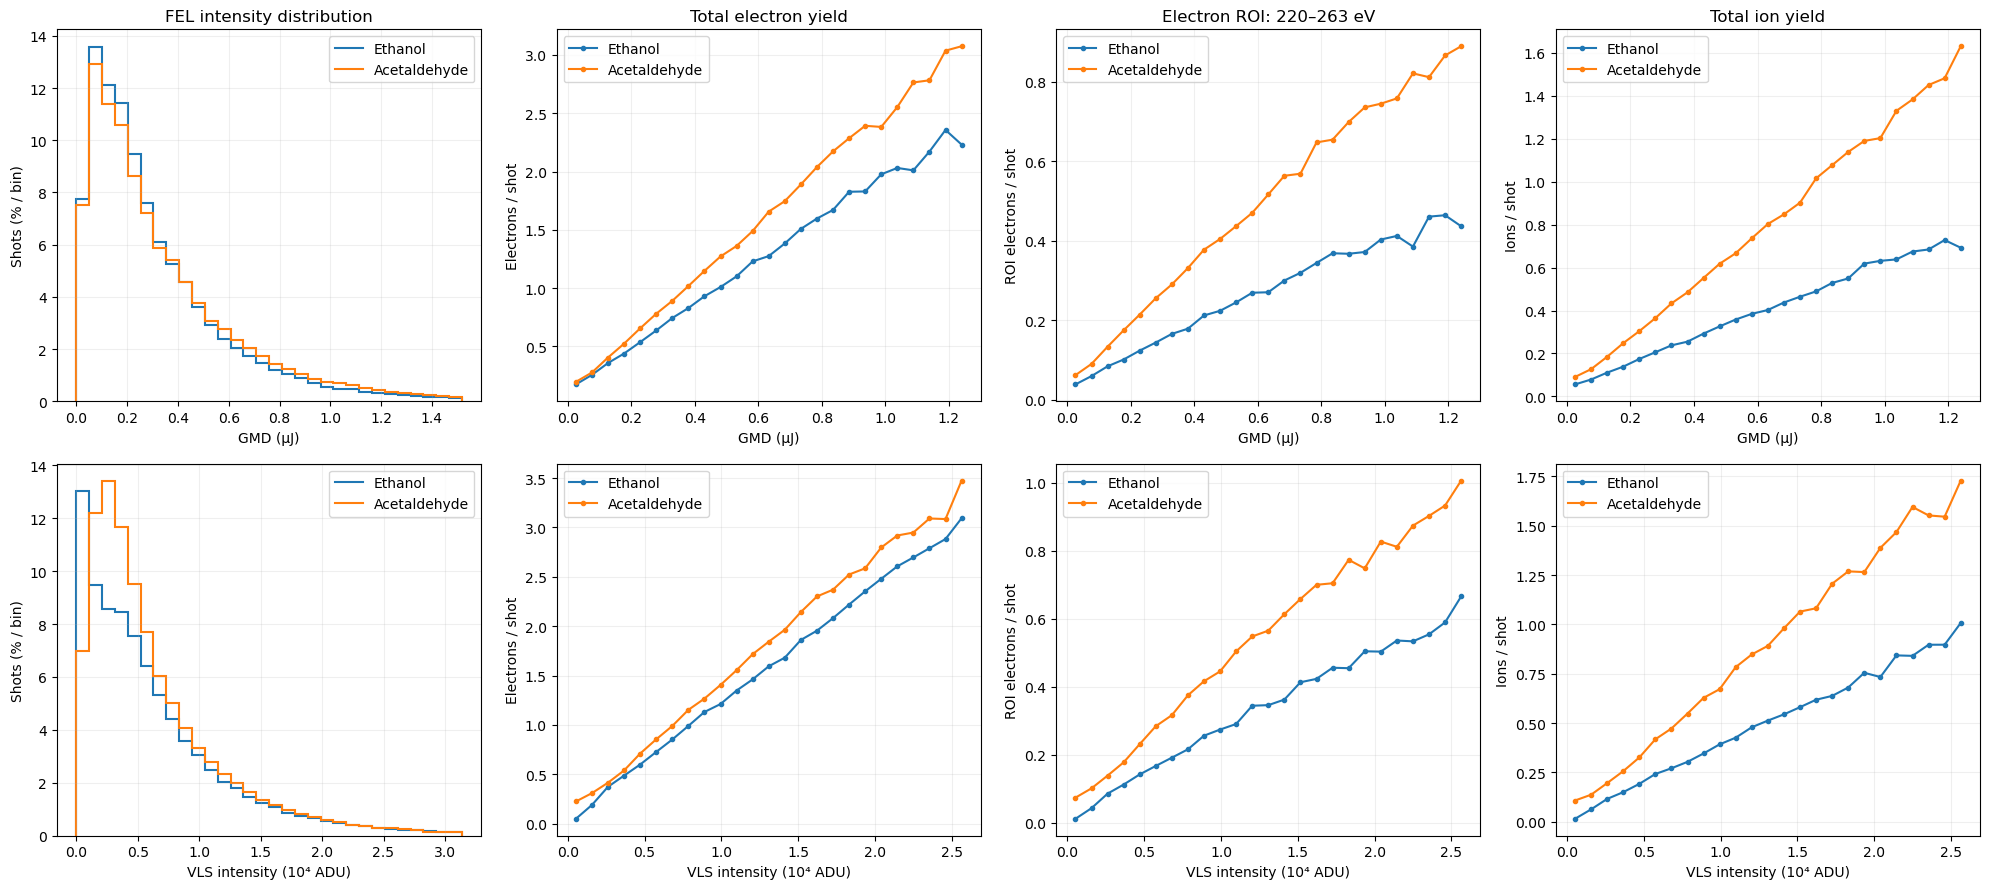

In [113]:
# ---- FEL intensity distributions and matched-intensity yields -----------

N_INTENSITY_BINS = 30
MIN_SHOTS = 500

molecule_colors = {
    'Ethanol': 'C0',
    'Acetaldehyde': 'C1'
}

fig, ax = plt.subplots(2, 4, figsize=(20, 9))

for row, (monitor_col, xlabel) in enumerate([
    (0, 'GMD (µJ)'),
    (1, 'VLS intensity (10⁴ ADU)')
]):

    # Common absolute intensity bins for both molecules.
    xmax = max(
        np.percentile(a[:, monitor_col], 99)
        for a in intensity_data.values()
    )

    edges = np.linspace(0, xmax, N_INTENSITY_BINS + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    counts = {}

    for molecule, a in intensity_data.items():

        counts[molecule] = np.histogram(
            a[:, monitor_col], bins=edges
        )[0]

    # Only compare yields where both molecules have enough shots.
    common = (
        (counts['Ethanol'] >= MIN_SHOTS) &
        (counts['Acetaldehyde'] >= MIN_SHOTS)
    )

    for molecule, a in intensity_data.items():

        color = molecule_colors[molecule]
        M = a[:, monitor_col]
        n = counts[molecule]

        # Intensity distribution.
        ax[row, 0].stairs(
            100 * n / len(a),
            edges,
            color=color,
            lw=1.5,
            label=molecule
        )

        # Mean electron/ion yield in each common intensity bin.
        for col, data_col in enumerate([2, 3, 4], start=1):

            sums = np.histogram(
                M, bins=edges,
                weights=a[:, data_col]
            )[0]

            y = np.divide(
                sums, n,
                out=np.full(len(n), np.nan),
                where=common
            )

            ax[row, col].plot(
                centres, y, '.-',
                color=color,
                label=molecule
            )

    for col in range(4):
        ax[row, col].set_xlabel(xlabel)
        ax[row, col].grid(alpha=0.2)
        ax[row, col].legend()

    ax[row, 0].set_ylabel('Shots (% / bin)')
    ax[row, 1].set_ylabel('Electrons / shot')
    ax[row, 2].set_ylabel('ROI electrons / shot')
    ax[row, 3].set_ylabel('Ions / shot')

ax[0, 0].set_title('FEL intensity distribution')
ax[0, 1].set_title('Total electron yield')
ax[0, 2].set_title(
    f'Electron ROI: {COMPARE_ROI[0]}–{COMPARE_ROI[1]} eV'
)
ax[0, 3].set_title('Total ion yield')

fig.tight_layout()
plt.show()

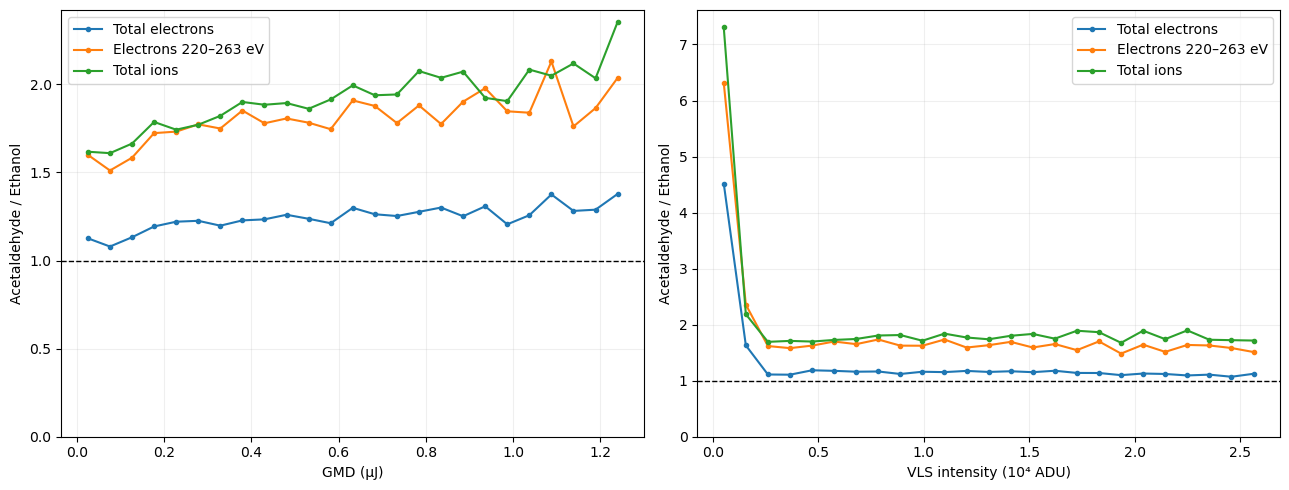

In [114]:
# ---- Acetaldehyde / ethanol at the same FEL intensity -------------------

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for aplot, (monitor_col, xlabel) in zip(ax, [
    (0, 'GMD (µJ)'),
    (1, 'VLS intensity (10⁴ ADU)')
]):

    xmax = max(
        np.percentile(a[:, monitor_col], 99)
        for a in intensity_data.values()
    )

    edges = np.linspace(0, xmax, N_INTENSITY_BINS + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    yields = {}
    counts = {}

    for molecule, a in intensity_data.items():

        n = np.histogram(a[:, monitor_col], bins=edges)[0]

        counts[molecule] = n
        yields[molecule] = []

        for col in [2, 3, 4]:

            sums = np.histogram(
                a[:, monitor_col],
                bins=edges,
                weights=a[:, col]
            )[0]

            y = np.divide(
                sums, n,
                out=np.full(len(n), np.nan),
                where=n >= MIN_SHOTS
            )

            yields[molecule].append(y)

    for j, label in enumerate([
        'Total electrons',
        f'Electrons {COMPARE_ROI[0]}–{COMPARE_ROI[1]} eV',
        'Total ions'
    ]):

        num = yields['Acetaldehyde'][j]
        den = yields['Ethanol'][j]

        ratio = np.divide(
            num, den,
            out=np.full_like(num, np.nan),
            where=(den > 0) & np.isfinite(num)
        )

        aplot.plot(centres, ratio, '.-', label=label)

    aplot.axhline(1, color='k', ls='--', lw=1)
    aplot.set_xlabel(xlabel)
    aplot.set_ylabel('Acetaldehyde / Ethanol')
    aplot.grid(alpha=0.2)
    aplot.legend()
    aplot.set_ylim(bottom=0)

fig.tight_layout()
plt.show()